# Setup

In [1]:
%pip install einops pandas matplotlib

# Imports

In [2]:
import gc
import itertools
import json
import random
import time
from importlib.metadata import version
from pathlib import Path

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

In [5]:
from einops import rearrange, repeat
from einops.layers.torch import Rearrange

# Config

In [6]:
# Fixed settings shared by all configurations.
SEED = 42
EPOCHS = 20
BATCH_SIZE = 256
EMBED_DIM = 96
MLP_DIM = 384
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT = 0.1

In [7]:
PATCH_SIZES = [4, 7]
DEPTHS = [4, 5, 6, 7, 8]
HEAD_COUNTS = [2, 3, 4]

CONFIGS = list(itertools.product(
    PATCH_SIZES, DEPTHS, HEAD_COUNTS
))
assert len(CONFIGS) == 30

In [8]:
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Runtime

In [9]:
OUT = Path("vit_outputs")
OUT.mkdir(parents=True, exist_ok=True)

In [10]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

In [11]:
def synchronize():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

In [12]:
SETTINGS = {
    "architecture": "instructor_vit_relu_v1",
    "torch_version": str(torch.__version__),
    "torchvision_version": version("torchvision"),
    "einops_version": version("einops"),
    "seed": SEED,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "embed_dim": EMBED_DIM,
    "mlp_dim": MLP_DIM,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "dropout": DROPOUT,
    "embedding_dropout": DROPOUT,
    "pooling": "cls",
    "activation": "ReLU",
    "dim_head_rule": "embed_dim // heads",
    "patch_sizes": PATCH_SIZES,
    "depths": DEPTHS,
    "head_counts": HEAD_COUNTS,
    "training_examples": 54000,
    "validation_examples": 6000,
    "normalization": "(x - 0.5) / 0.5",
    "gradient_clip_norm": 1.0,
    "scheduler": "CosineAnnealingLR"
}

settings_path = OUT / "settings.json"

if settings_path.exists():
    with open(settings_path) as f:
        saved_settings = json.load(f)

    if saved_settings != SETTINGS:
        raise ValueError(
            "This directory contains a different experiment. "
            "Choose a new OUT directory."
        )
else:
    with open(settings_path, "w") as f:
        json.dump(SETTINGS, f, indent=2)

In [13]:
set_seed(SEED)

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Number of configurations:", len(CONFIGS))

Device: cuda
GPU: Tesla T4
Number of configurations: 30


# Data

In [14]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5,), std=(0.5,))
])

In [15]:
full_train = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_data = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

assert len(full_train) == 60000
assert len(test_data) == 10000

100%|██████████| 26.4M/26.4M [00:01<00:00, 20.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 331kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.65MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 12.3MB/s]


In [16]:
train_data, val_data = random_split(
    full_train,
    [54000, 6000],
    generator=torch.Generator().manual_seed(SEED)
)

np.savez(
    OUT / "split_indices.npz",
    train_indices=np.asarray(train_data.indices),
    validation_indices=np.asarray(val_data.indices)
)

In [17]:
def make_loader(dataset, shuffle=False):
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda"),
        drop_last=False,
        generator=torch.Generator().manual_seed(SEED)
    )


val_loader = make_loader(val_data)
test_loader = make_loader(test_data)

In [18]:
images, labels = next(iter(make_loader(train_data)))

assert images.shape[1:] == (1, 28, 28)
assert labels.dtype == torch.long

print("Training examples:", len(train_data))
print("Validation examples:", len(val_data))
print("Test examples:", len(test_data))
print("Image batch shape:", tuple(images.shape))

Training examples: 54000
Validation examples: 6000
Test examples: 10000
Image batch shape: (256, 1, 28, 28)


# Embedding

In [19]:
def pair(value):
    return value if isinstance(value, tuple) else (value, value)

In [20]:
class PreNorm(nn.Module):
    def __init__(self, dim, fn):
        super().__init__()
        self.norm = nn.LayerNorm(dim)
        self.fn = fn

    def forward(self, x):
        return self.fn(self.norm(x))

In [21]:
class FeedForward(nn.Module):
    def __init__(self, dim, hidden_dim, dropout=0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, dim),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.net(x)

# Attention

In [22]:
class Attention(nn.Module):
    def __init__(self, dim, heads=8, dim_head=64, dropout=0.0):
        super().__init__()

        inner_dim = heads * dim_head
        project_out = not (heads == 1 and dim_head == dim)

        self.heads = heads
        self.scale = dim_head ** -0.5

        self.to_qkv = nn.Linear(
            dim, 3 * inner_dim, bias=False
        )

        self.attend = nn.Softmax(dim=-1)

        self.to_out = (
            nn.Sequential(
                nn.Linear(inner_dim, dim),
                nn.Dropout(dropout)
            )
            if project_out
            else nn.Identity()
        )

    def forward(self, x):
        qkv = self.to_qkv(x).chunk(3, dim=-1)

        q, k, v = [
            rearrange(
                tensor,
                "b n (h d) -> b h n d",
                h=self.heads
            )
            for tensor in qkv
        ]

        scores = torch.matmul(
            q, k.transpose(-1, -2)
        ) * self.scale

        weights = self.attend(scores)
        out = torch.matmul(weights, v)

        out = rearrange(
            out,
            "b h n d -> b n (h d)"
        )

        return self.to_out(out)

# Transformer

In [23]:
class Transformer(nn.Module):
    def __init__(
        self,
        dim,
        depth,
        heads,
        dim_head,
        mlp_dim,
        dropout=0.0
    ):
        super().__init__()

        self.layers = nn.ModuleList([
            nn.ModuleList([
                PreNorm(
                    dim,
                    Attention(
                        dim=dim,
                        heads=heads,
                        dim_head=dim_head,
                        dropout=dropout
                    )
                ),
                PreNorm(
                    dim,
                    FeedForward(
                        dim=dim,
                        hidden_dim=mlp_dim,
                        dropout=dropout
                    )
                )
            ])
            for _ in range(depth)
        ])

    def forward(self, x):
        for attention, feedforward in self.layers:
            x = x + attention(x)
            x = x + feedforward(x)
        return x

# ViT

In [24]:
class ViT(nn.Module):
    def __init__(
        self,
        *,
        image_size,
        patch_size,
        num_classes,
        dim,
        depth,
        heads,
        mlp_dim,
        pool="cls",
        channels=1,
        dim_head=64,
        dropout=0.0,
        emb_dropout=0.0
    ):
        super().__init__()

        image_height, image_width = pair(image_size)
        patch_height, patch_width = pair(patch_size)

        if (
            image_height % patch_height != 0
            or image_width % patch_width != 0
        ):
            raise ValueError(
                "Image dimensions must be divisible by patch size."
            )

        if pool not in {"cls", "mean"}:
            raise ValueError("pool must be 'cls' or 'mean'.")

        self.image_size = (image_height, image_width)
        self.channels = channels

        num_patches = (
            (image_height // patch_height)
            * (image_width // patch_width)
        )

        patch_dim = channels * patch_height * patch_width

        self.to_patch_embedding = nn.Sequential(
            Rearrange(
                "b c (h p1) (w p2) -> b (h w) (p1 p2 c)",
                p1=patch_height,
                p2=patch_width
            ),
            nn.Linear(patch_dim, dim)
        )

        self.pos_embedding = nn.Parameter(
            torch.randn(1, num_patches + 1, dim)
        )
        self.cls_token = nn.Parameter(
            torch.randn(1, 1, dim)
        )

        self.dropout = nn.Dropout(emb_dropout)

        self.transformer = Transformer(
            dim=dim,
            depth=depth,
            heads=heads,
            dim_head=dim_head,
            mlp_dim=mlp_dim,
            dropout=dropout
        )

        self.pool = pool

        self.mlp_head = nn.Sequential(
            nn.LayerNorm(dim),
            nn.Linear(dim, num_classes)
        )

    def forward(self, images):
        if images.ndim != 4:
            raise ValueError("Expected input shape (B, C, H, W).")

        if (
            images.size(1) != self.channels
            or tuple(images.shape[-2:]) != self.image_size
        ):
            raise ValueError("Unexpected channels or image dimensions.")

        x = self.to_patch_embedding(images)
        batch_size, num_patches, _ = x.shape

        cls_tokens = repeat(
            self.cls_token,
            "1 1 d -> b 1 d",
            b=batch_size
        )

        x = torch.cat([cls_tokens, x], dim=1)
        x = x + self.pos_embedding[:, :num_patches + 1]
        x = self.dropout(x)

        x = self.transformer(x)

        x = x[:, 0] if self.pool == "cls" else x.mean(dim=1)

        return self.mlp_head(x)

# Factory

In [25]:
def make_model(patch_size, depth, heads):
    if EMBED_DIM % heads != 0:
        raise ValueError(
            "EMBED_DIM must be divisible by heads for this experiment."
        )

    return ViT(
        image_size=28,
        patch_size=patch_size,
        num_classes=10,
        channels=1,
        dim=EMBED_DIM,
        depth=depth,
        heads=heads,
        dim_head=EMBED_DIM // heads,
        mlp_dim=MLP_DIM,
        pool="cls",
        dropout=DROPOUT,
        emb_dropout=DROPOUT
    )

# Validation

In [26]:
for patch_size, heads in itertools.product(
    PATCH_SIZES, HEAD_COUNTS
):
    set_seed(SEED)

    model = make_model(
        patch_size=patch_size,
        depth=4,
        heads=heads
    )

    dummy_images = torch.randn(2, 1, 28, 28)
    dummy_labels = torch.tensor([0, 1], dtype=torch.long)

    logits = model(dummy_images)

    assert logits.shape == (2, 10)
    assert torch.isfinite(logits).all()

    loss = nn.CrossEntropyLoss()(logits, dummy_labels)
    loss.backward()

    patch_tokens = (28 // patch_size) ** 2

    print(
        f"Passed: patch={patch_size}, heads={heads}, "
        f"patch tokens={patch_tokens}, "
        f"sequence length={patch_tokens + 1}"
    )

    del model, dummy_images, dummy_labels, logits, loss

gc.collect()

Passed: patch=4, heads=2, patch tokens=49, sequence length=50
Passed: patch=4, heads=3, patch tokens=49, sequence length=50
Passed: patch=4, heads=4, patch tokens=49, sequence length=50
Passed: patch=7, heads=2, patch tokens=16, sequence length=17
Passed: patch=7, heads=3, patch tokens=16, sequence length=17
Passed: patch=7, heads=4, patch tokens=16, sequence length=17


30

# Training

In [27]:
criterion = nn.CrossEntropyLoss()

In [28]:
def train_one_epoch(model, loader, optimizer):
    model.train()

    loss_sum = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)
        loss = criterion(logits, labels)

        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite training loss encountered.")

        loss.backward()

        nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0,
            error_if_nonfinite=True
        )

        optimizer.step()

        batch_size = labels.size(0)
        loss_sum += loss.item() * batch_size
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += batch_size

    return loss_sum / total, 100.0 * correct / total

In [29]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()

    loss_sum = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        logits = model(images)
        loss = criterion(logits, labels)

        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite evaluation loss encountered.")

        batch_size = labels.size(0)
        loss_sum += loss.item() * batch_size
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += batch_size

    return loss_sum / total, 100.0 * correct / total

In [30]:
def run_name(patch_size, depth, heads):
    return f"patch{patch_size}_layers{depth}_heads{heads}"

# Experiment

In [31]:
for run_index, (patch_size, depth, heads) in enumerate(
    CONFIGS, start=1
):
    name = run_name(patch_size, depth, heads)
    checkpoint_path = OUT / f"{name}.pt"

    if checkpoint_path.exists():
        print(f"[{run_index}/30] Already completed: {name}")
        continue

    set_seed(SEED)
    train_loader = make_loader(train_data, shuffle=True)

    model = make_model(
        patch_size, depth, heads
    ).to(DEVICE)

    parameter_count = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=EPOCHS
    )

    best_val_acc = -1.0
    best_val_loss = float("inf")
    best_epoch = 0
    best_state = None
    history = []

    synchronize()
    start = time.perf_counter()

    for epoch in range(1, EPOCHS + 1):
        epoch_lr = optimizer.param_groups[0]["lr"]

        train_loss, train_acc = train_one_epoch(
            model, train_loader, optimizer
        )

        val_loss, val_acc = evaluate(
            model, val_loader
        )

        history.append({
            "epoch": epoch,
            "learning_rate": epoch_lr,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "validation_loss": val_loss,
            "validation_accuracy": val_acc
        })

        improved = (
            val_acc > best_val_acc
            or (
                val_acc == best_val_acc
                and val_loss < best_val_loss
            )
        )

        if improved:
            best_val_acc = val_acc
            best_val_loss = val_loss
            best_epoch = epoch

            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

        scheduler.step()

        print(
            f"[{run_index}/30] {name}, "
            f"epoch {epoch:02d}/{EPOCHS}: "
            f"train loss={train_loss:.4f}, "
            f"train acc={train_acc:.2f}%, "
            f"val acc={val_acc:.2f}%"
        )

    synchronize()
    training_seconds = time.perf_counter() - start

    pd.DataFrame(history).to_csv(
        OUT / f"{name}_history.csv",
        index=False
    )

    checkpoint = {
        "state_dict": best_state,
        "settings": SETTINGS,
        "patch_size": patch_size,
        "layers": depth,
        "heads": heads,
        "parameters": parameter_count,
        "best_epoch": best_epoch,
        "validation_accuracy": best_val_acc,
        "validation_loss": best_val_loss,
        "training_seconds": training_seconds
    }

    temporary_path = OUT / f"{name}.tmp"
    torch.save(checkpoint, temporary_path)
    temporary_path.replace(checkpoint_path)

    del model, optimizer, scheduler, best_state, checkpoint
    gc.collect()

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

[1/30] patch4_layers4_heads2, epoch 01/20: train loss=0.8609, train acc=68.59%, val acc=80.68%
[1/30] patch4_layers4_heads2, epoch 02/20: train loss=0.5047, train acc=81.77%, val acc=83.73%
[1/30] patch4_layers4_heads2, epoch 03/20: train loss=0.4407, train acc=83.90%, val acc=85.38%
[1/30] patch4_layers4_heads2, epoch 04/20: train loss=0.4145, train acc=84.91%, val acc=84.90%
[1/30] patch4_layers4_heads2, epoch 05/20: train loss=0.3877, train acc=85.71%, val acc=86.50%
[1/30] patch4_layers4_heads2, epoch 06/20: train loss=0.3713, train acc=86.26%, val acc=86.63%
[1/30] patch4_layers4_heads2, epoch 07/20: train loss=0.3540, train acc=86.93%, val acc=87.22%
[1/30] patch4_layers4_heads2, epoch 08/20: train loss=0.3403, train acc=87.41%, val acc=87.52%
[1/30] patch4_layers4_heads2, epoch 09/20: train loss=0.3269, train acc=87.82%, val acc=87.53%
[1/30] patch4_layers4_heads2, epoch 10/20: train loss=0.3156, train acc=88.20%, val acc=88.28%
[1/30] patch4_layers4_heads2, epoch 11/20: train l

# Evaluation

In [32]:
results = []

for patch_size, depth, heads in CONFIGS:
    name = run_name(patch_size, depth, heads)
    checkpoint_path = OUT / f"{name}.pt"

    if not checkpoint_path.exists():
        raise FileNotFoundError(
            f"Missing completed configuration: {name}"
        )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    if checkpoint["settings"] != SETTINGS:
        raise ValueError(f"Settings mismatch for {name}")

    model = make_model(
        patch_size, depth, heads
    ).to(DEVICE)

    model.load_state_dict(checkpoint["state_dict"])

    test_loss, test_acc = evaluate(model, test_loader)

    results.append({
        "patch_size": f"{patch_size}x{patch_size}",
        "patch_tokens": (28 // patch_size) ** 2,
        "sequence_length": (28 // patch_size) ** 2 + 1,
        "layers": depth,
        "heads": heads,
        "parameters": checkpoint["parameters"],
        "best_epoch": checkpoint["best_epoch"],
        "validation_accuracy": checkpoint["validation_accuracy"],
        "validation_loss": checkpoint["validation_loss"],
        "test_accuracy": test_acc,
        "test_loss": test_loss,
        "training_minutes": checkpoint["training_seconds"] / 60.0
    })

    print(f"{name}: test accuracy = {test_acc:.2f}%")

    del model, checkpoint
    gc.collect()

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

patch4_layers4_heads2: test accuracy = 89.00%
patch4_layers4_heads3: test accuracy = 89.27%
patch4_layers4_heads4: test accuracy = 89.49%
patch4_layers5_heads2: test accuracy = 89.20%
patch4_layers5_heads3: test accuracy = 89.65%
patch4_layers5_heads4: test accuracy = 89.67%
patch4_layers6_heads2: test accuracy = 89.45%
patch4_layers6_heads3: test accuracy = 89.76%
patch4_layers6_heads4: test accuracy = 90.12%
patch4_layers7_heads2: test accuracy = 89.78%
patch4_layers7_heads3: test accuracy = 90.10%
patch4_layers7_heads4: test accuracy = 89.81%
patch4_layers8_heads2: test accuracy = 89.43%
patch4_layers8_heads3: test accuracy = 90.31%
patch4_layers8_heads4: test accuracy = 89.90%
patch7_layers4_heads2: test accuracy = 89.05%
patch7_layers4_heads3: test accuracy = 89.33%
patch7_layers4_heads4: test accuracy = 90.03%
patch7_layers5_heads2: test accuracy = 89.16%
patch7_layers5_heads3: test accuracy = 89.57%
patch7_layers5_heads4: test accuracy = 89.56%
patch7_layers6_heads2: test accura

# Results

In [ ]:
results_df = pd.DataFrame(results).sort_values(
    ["patch_size", "layers", "heads"]
).reset_index(drop=True)

assert len(results_df) == 30
assert not results_df.duplicated(
    ["patch_size", "layers", "heads"]
).any()
assert results_df["test_accuracy"].between(0, 100).all()

results_df.to_csv(
    OUT / "all_results.csv",
    index=False
)

display(results_df.round(3))

# Table

In [34]:
accuracy_table = results_df.pivot(
    index=["patch_size", "layers"],
    columns="heads",
    values="test_accuracy"
).rename(columns={
    2: "2 heads (%)",
    3: "3 heads (%)",
    4: "4 heads (%)"
})

assert accuracy_table.shape == (10, 3)
assert not accuracy_table.isna().any().any()

accuracy_table.to_csv(
    OUT / "submission_accuracy_table.csv",
    float_format="%.2f"
)

display(accuracy_table.round(2))

heads              2 heads (%)  3 heads (%)  4 heads (%)
patch_size layers                                       
4x4        4             89.00        89.27        89.49
           5             89.20        89.65        89.67
           6             89.45        89.76        90.12
           7             89.78        90.10        89.81
           8             89.43        90.31        89.90
7x7        4             89.05        89.33        90.03
           5             89.16        89.57        89.56
           6             89.50        89.47        89.55
           7             89.99        90.19        90.07
           8             90.14        89.82        90.11

# Selection

In [50]:
selected = results_df.sort_values(
    ["validation_accuracy", "validation_loss"],
    ascending=[False, True],
    kind="stable"
).iloc[0]

selected.to_frame(name="value").to_csv(
    OUT / "validation_selected_model.csv"
)

print("\nConfiguration selected by validation performance:")
print(
    f"Patch size: {selected['patch_size']}\n"
    f"Layers: {int(selected['layers'])}\n"
    f"Heads: {int(selected['heads'])}\n"
    f"Selected epoch: {int(selected['best_epoch'])}\n"
    f"Validation accuracy: "
    f"{selected['validation_accuracy']:.2f}%\n"
    f"Test accuracy: {selected['test_accuracy']:.2f}%"
)


Configuration selected by validation performance:
Patch size: 7x7
Layers: 8
Heads: 4
Selected epoch: 19
Validation accuracy: 90.68%
Test accuracy: 90.11%


# Accuracy

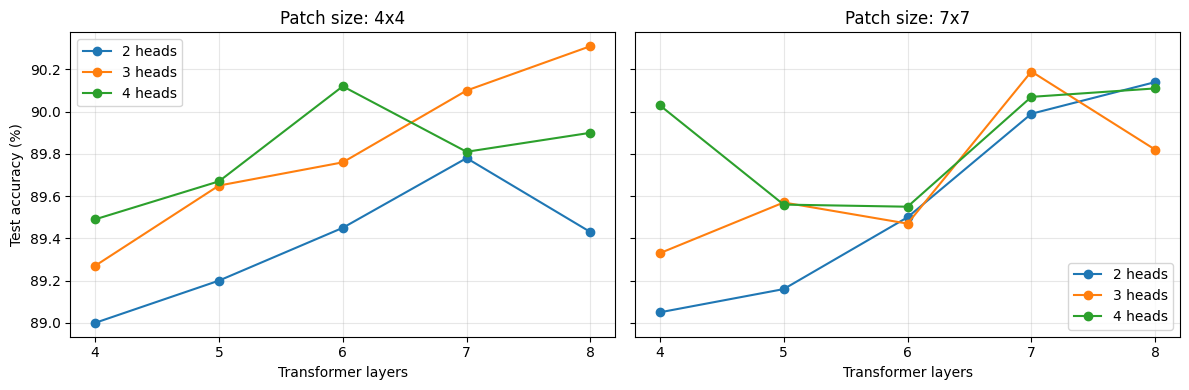

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, patch in zip(axes, ["4x4", "7x7"]):
    for heads in HEAD_COUNTS:
        subset = results_df[
            (results_df["patch_size"] == patch)
            & (results_df["heads"] == heads)
        ].sort_values("layers")

        ax.plot(
            subset["layers"],
            subset["test_accuracy"],
            marker="o",
            label=f"{heads} heads"
        )

    ax.set_title(f"Patch size: {patch}")
    ax.set_xlabel("Transformer layers")
    ax.set_xticks(DEPTHS)
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Test accuracy (%)")
fig.tight_layout()
fig.savefig(
    OUT / "accuracy_vs_depth.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Curves

In [59]:
#training curves for the validation selected model
selected_patch = int(selected["patch_size"].split("x")[0])
selected_depth = int(selected["layers"])
selected_heads = int(selected["heads"])

name = run_name(
    selected_patch, selected_depth, selected_heads
)

history = pd.read_csv(OUT / f"{name}_history.csv")

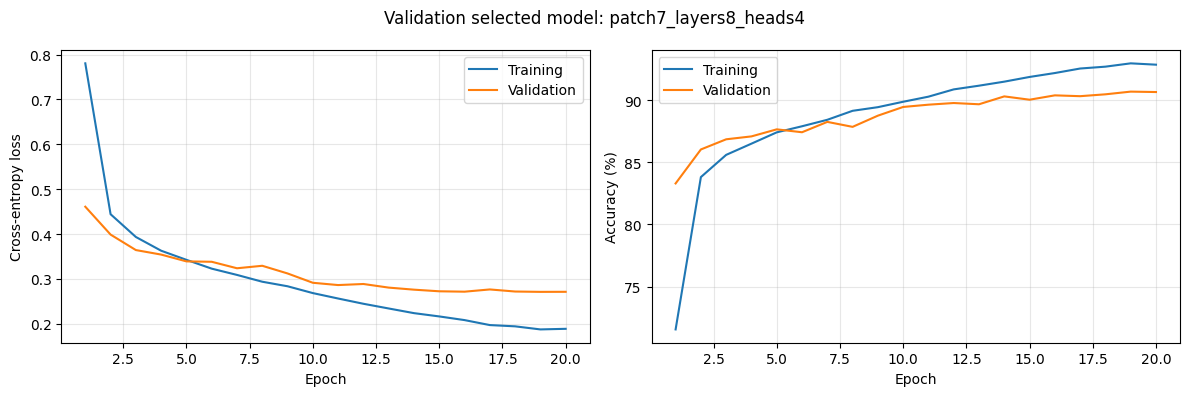

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

#left plot - loss
axes[0].plot(
    history["epoch"],
    history["train_loss"],
    label="Training"
)
axes[0].plot(
    history["epoch"],
    history["validation_loss"],
    label="Validation"
)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

#right plot - accuracy
axes[1].plot(
    history["epoch"],
    history["train_accuracy"],
    label="Training"
)
axes[1].plot(
    history["epoch"],
    history["validation_accuracy"],
    label="Validation"
)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

#layout and rendering
fig.suptitle(f"Validation selected model: {name}")
fig.tight_layout()
fig.savefig(
    OUT / "selected_model_training_curves.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()